# Monthly ONDJFMA anomaly correlations (autocorrelation-aware)

Answers a different question from the trimmed correlation matrix's DJFM
winter-mean correlations: not "do winters with a stronger index tend to
have less ice", but "in months when this index is anomalous, is the
ice/CAO state anomalous at the same time, with no lag built in".

- **Targets**: GS ice monthly anomaly, CAO_early (Oct-Jan months of the
  monthly CAO series), CAO_late (Feb-Apr months).
- **Predictors**: climate indices, monthly, ONDJFMA-restricted.
- **Significance**: plain Pearson alongside an effective-N correction for
  within-winter month-to-month autocorrelation (Bretherton et al. 1999),
  with lag-1 estimated only from genuine consecutive-month pairs within a
  winter -- the Apr-to-October gap between winters is excluded from that
  estimate, not treated as an ordinary 1-month lag.

**This notebook could not be run against real ERA5/OSISAF data in the
environment that built it.** The statistical machinery is validated
against synthetic data (see SELFTEST); the real-data path is
syntax-checked only. Run SELFTEST first.

Author: Chris Barrell


In [1]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats as scipy_stats
import shapely.geometry as sgeom
import regionmask
import metpy.calc as mpcalc
from metpy.units import units
from pathlib import Path
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

import sys
sys.path.append('..')
from utils.logger import (setup_logger, log_data_loading, log_processing_step,
                          log_output_file, log_completion, log_error)

logger = setup_logger('monthly_ondjfma_correlations', config_path='../config.yaml')
start_time = datetime.now()


INFO     | ======================================================================
INFO     | Starting analysis: monthly_ondjfma_correlations
INFO     | Log file: outputs/logs/monthly_ondjfma_correlations_20260916_144736.log
INFO     | Timestamp: 2026-09-16 14:47:36
INFO     | ======================================================================


## Configuration


In [2]:
# ---- ERA5 / CAO recomputation -- copied unchanged from figure_06 -------
ERA5_DIR      = Path('../../era5/')
ERA5_PATTERN  = 'era5_*_Arctic.nc'
DATA_END_DATE = '2026-04-30'

GREENLAND_SEA_COORDS = [
    (-22, 71), (-8.5, 71), (12, 79), (-21, 79), (-28, 73), (-22, 71)
]
PRESSURE_LEVEL = 850     # hPa
SIC_THRESHOLD  = 0.15    # 15% -- CAO domain excludes ice-covered cells

# ---- Sea ice source (same convention as figure_01 / figure_07) ---------
ICE_NC_MONTHLY   = Path('/local/jbj13rpu/Documents/ROVER/gs_ice_study/notebooks/'
                        'outputs/processed_data/osisaf_sii_v3/osisaf_sii_v3_all_regions.nc')
ICE_VAR          = 'ice_extent_greenland_monthly'
OSISAF_DAILY_DIR = Path('../../osi-sea_ice_index/')
OSISAF_GS_REGION = 'fram'

# ---- Climate indices -- same sources as figure_index_phases ------------
CLIMATE_NC = Path('./outputs/processed_data/climate_indices/all_climate_indices.nc')
INDEX_RAW_DIR = Path('/local/jbj13rpu/Documents/ROVER/climate_indices/raw')

INDEX_SPEC = [
    dict(label='GBI',   nc_aliases=['GBI_UL', 'GBI', 'gbi'],
         raw_file='gbi_mon.csv', reader='psl_csv'),
    dict(label='NAO',   nc_aliases=['NAO', 'nao'],
         raw_file='NAO.data', reader='psl_data'),
    dict(label='AO',    nc_aliases=['AO', 'ao'],
         raw_file='AO.data', reader='psl_data'),
    dict(label='PDO',   nc_aliases=['PDO', 'pdo'],
         raw_file='PDO.data', reader='psl_data'),
    dict(label='TPQD',  nc_aliases=['TPQD', 'tpqd'],
         raw_file=None, reader=None),
    dict(label='SCAND', nc_aliases=['SCAND', 'scand'],
         raw_file='SCAND.data', reader='psl_data'),
    dict(label='AD',    nc_aliases=['AD', 'ad'],
         raw_file=None, reader=None),
    dict(label='NINO3.4', nc_aliases=['NINO34', 'nino34'],
         raw_file='NINO34.data', reader='psl_data'),
]
MISSING_SENTINELS = [-999.0, -99.9, -99.99, -9999.0, -99.0]

# ---- Seasons -------------------------------------------------------------
EARLY_WINTER_MONTHS = [10, 11, 12, 1]     # ONDJ
LATE_WINTER_MONTHS  = [2, 3, 4]           # FMA
ONDJFMA_MONTHS = EARLY_WINTER_MONTHS + LATE_WINTER_MONTHS

# Sequence index within a winter, 1..7, used ONLY to find genuine
# consecutive-month pairs for the lag-1 autocorrelation estimate -- NOT
# used anywhere else (correlations themselves use calendar months/years).
WINTER_SEQUENCE = {10: 1, 11: 2, 12: 3, 1: 4, 2: 5, 3: 6, 4: 7}

# ---- Analysis period -----------------------------------------------------
ANALYSIS_START = 1979
ANALYSIS_END   = 2025

# ---- Significance ---------------------------------------------------------
P_THRESHOLD = 0.05

# ---- Style / output --------------------------------------------------------
CMAP = 'RdBu_r'
VLIM = 0.9
DPI  = 600
OUTPUT_DIR         = Path('./outputs/figures/')
PROCESSED_DIR      = Path('./outputs/processed_data/monthly_ondjfma_correlations')
OUTPUT_METHODS_DIR = Path('./outputs/methods')
for d in (OUTPUT_DIR, PROCESSED_DIR, OUTPUT_METHODS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Set True to run the synthetic validation before touching real data.
SELFTEST = True


## Winter-year labelling

Shared by every series in this notebook: a winter is labelled by the year
in which January/April falls (Oct-Dec 1994 and Jan-Apr 1995 are both
"winter 1995"), matching figure_06 / figure_07 / figure_index_phases.


In [3]:
def winter_year(month, year):
    """Vectorised: month/year arrays -> winter-year labels."""
    month = np.asarray(month)
    year = np.asarray(year)
    return np.where(month >= 10, year + 1, year)


## Effective-N significance (gap-aware lag-1 autocorrelation)

The core piece of new statistical machinery. `lag1_within_winter` pools
lag-1 autocorrelation from genuine consecutive-month pairs only --
Oct→Nov, Nov→Dec, ..., Mar→Apr within the SAME winter-year -- and
explicitly excludes the Apr→October pair spanning two different winters,
which is not a real 1-month gap and would distort the estimate if included
naively on a concatenated ONDJFMA series.


In [4]:
def lag1_within_winter(df):
    """Pooled lag-1 autocorrelation from genuine within-winter
    consecutive-month pairs only.

    df: DataFrame with columns ['winter_year', 'seq', 'value'], one row
    per (winter, month). Returns the correlation between value(seq) and
    value(seq+1) pooled across all winters and valid seq transitions,
    or np.nan if fewer than ~10 valid pairs are available.
    """
    df = df.dropna(subset=['value']).sort_values(['winter_year', 'seq'])
    pairs_x, pairs_y = [], []
    for wy, grp in df.groupby('winter_year'):
        grp = grp.set_index('seq')['value']
        for seq in grp.index:
            if (seq + 1) in grp.index:      # genuine same-winter adjacency
                pairs_x.append(grp[seq])
                pairs_y.append(grp[seq + 1])
    if len(pairs_x) < 10:
        return np.nan
    return np.corrcoef(pairs_x, pairs_y)[0, 1]


def effective_n_pearson(x, y, wy_x, seq_x, wy_y, seq_y):
    """Pearson r with both plain and effective-N (Bretherton et al. 1999)
    significance.

    x, y: aligned value arrays (already restricted to common valid months).
    wy_x/seq_x, wy_y/seq_y: matching winter-year and within-winter sequence
    arrays for x and y respectively, used only for the lag-1 estimates
    (x and y may have different missingness patterns, e.g. CAO_early is
    only defined for 4 of the 7 ONDJFMA months, so their own lag-1
    autocorrelations are estimated independently on their own valid data,
    not on the intersected x/y pairs).

    Returns dict with r, n, p_plain, r1x, r1y, n_eff, p_effn.
    """
    n = len(x)
    if n < 5:
        return dict(r=np.nan, n=n, p_plain=np.nan, r1x=np.nan, r1y=np.nan,
                    n_eff=np.nan, p_effn=np.nan)

    r, p_plain = scipy_stats.pearsonr(x, y)

    r1x = lag1_within_winter(pd.DataFrame({'winter_year': wy_x, 'seq': seq_x, 'value': x}))
    r1y = lag1_within_winter(pd.DataFrame({'winter_year': wy_y, 'seq': seq_y, 'value': y}))

    if np.isnan(r1x) or np.isnan(r1y):
        return dict(r=r, n=n, p_plain=p_plain, r1x=r1x, r1y=r1y,
                    n_eff=np.nan, p_effn=np.nan)

    denom = 1 + r1x * r1y
    n_eff = n * (1 - r1x * r1y) / denom if denom > 0 else np.nan

    if not np.isfinite(n_eff) or n_eff <= 3 or abs(r) >= 1:
        p_effn = np.nan
    else:
        dof = n_eff - 2
        t_stat = r * np.sqrt(dof / (1 - r ** 2))
        p_effn = 2 * scipy_stats.t.sf(abs(t_stat), dof)

    return dict(r=r, n=n, p_plain=p_plain, r1x=r1x, r1y=r1y,
               n_eff=n_eff, p_effn=p_effn)


## Self-test on synthetic data

Validates the gap-aware lag-1 estimate and the effective-N correction
before any real data is touched. Two checks:

1. **Gap exclusion works**: an AR(1) process regenerated fresh (i.e.
   genuinely independent) at the start of every winter should have its
   lag-1 autocorrelation recovered correctly by the WITHIN-winter
   estimator; a naive estimator that doesn't exclude the Apr→Oct gap
   would underestimate it, since a fraction of the "lag-1" pairs it uses
   are actually the discontinuity.
2. **Effective-N reduces false significance**: two independent but
   strongly autocorrelated series, correlated over many ONDJFMA months,
   should show p_plain far smaller (falsely more significant) than
   p_effn, on average, across repeated trials.


In [5]:
if SELFTEST:
    rng = np.random.default_rng(0)
    n_years = 40
    true_phi = 0.7

    def make_ar1_within_winter(phi, rng, n_years):
        """AR(1) series, regenerated (reset) at the start of each winter
        -- i.e. genuinely no autocorrelation carried across the Apr->Oct
        gap, matching the real-world assumption the gap-exclusion logic
        relies on.
        """
        rows = []
        for wy in range(1980, 1980 + n_years):
            val = rng.normal()
            for seq in range(1, 8):
                val = phi * val + np.sqrt(1 - phi ** 2) * rng.normal()
                rows.append((wy, seq, val))
        return pd.DataFrame(rows, columns=['winter_year', 'seq', 'value'])

    # --- check 1: gap-aware lag-1 recovers true_phi -----------------------
    df_ar1 = make_ar1_within_winter(true_phi, rng, n_years)
    r1_est = lag1_within_winter(df_ar1)
    print(f'True phi={true_phi:.2f}  Estimated (gap-aware) r1={r1_est:.3f}')
    assert abs(r1_est - true_phi) < 0.08, 'gap-aware lag-1 estimate off'

    # naive estimator that does NOT exclude the gap, for comparison only
    df_sorted = df_ar1.sort_values(['winter_year', 'seq']).reset_index(drop=True)
    naive_r1 = np.corrcoef(df_sorted['value'].values[:-1],
                           df_sorted['value'].values[1:])[0, 1]
    print(f'Naive (gap-INCLUDED) r1={naive_r1:.3f}  '
         f'(expected further from {true_phi:.2f} than the gap-aware estimate)')

    # --- check 2: effective-N reduces false-positive rate -----------------
    n_trials = 200
    false_pos_plain = false_pos_effn = 0
    for _ in range(n_trials):
        dfx = make_ar1_within_winter(true_phi, rng, n_years)
        dfy = make_ar1_within_winter(true_phi, rng, n_years)   # independent of x
        common = dfx.merge(dfy, on=['winter_year', 'seq'], suffixes=('_x', '_y'))
        res = effective_n_pearson(
            common['value_x'].values, common['value_y'].values,
            common['winter_year'].values, common['seq'].values,
            common['winter_year'].values, common['seq'].values)
        false_pos_plain += res['p_plain'] < 0.05
        false_pos_effn  += (res['p_effn'] < 0.05) if np.isfinite(res['p_effn']) else 0

    print(f'False-positive rate (nominal 5%): '
         f'plain={false_pos_plain/n_trials:.1%}  '
         f'effective-N={false_pos_effn/n_trials:.1%}')
    assert false_pos_plain / n_trials > false_pos_effn / n_trials, (
        'effective-N correction did not reduce the false-positive rate '
        '-- something is wrong before trusting real-data results'
    )

    print('SELFTEST passed')


True phi=0.70  Estimated (gap-aware) r1=0.692
Naive (gap-INCLUDED) r1=0.557  (expected further from 0.70 than the gap-aware estimate)
False-positive rate (nominal 5%): plain=22.0%  effective-N=3.0%
SELFTEST passed


## Recompute CAO index at monthly resolution

Identical method to figure_06's `calculate_cao_index`: same Greenland Sea
polygon, same land mask, same 15% SIC threshold, same 850 hPa potential
temperature calculation. figure_06 only saves the ONDJ/FMA seasonal means,
not this monthly series, so it's recomputed here rather than loaded.


In [6]:
def create_greenland_sea_mask(ds, lon_name='longitude', lat_name='latitude'):
    polygon = sgeom.Polygon(GREENLAND_SEA_COORDS)
    region = regionmask.Regions([polygon], names=['Greenland Sea'], abbrevs=['GS'])
    mask = region.mask(ds[lon_name], ds[lat_name])
    return (mask == 0)


def load_era5_data():
    file_list = sorted(ERA5_DIR.glob(ERA5_PATTERN))
    if not file_list:
        raise FileNotFoundError(f'No files matching {ERA5_DIR / ERA5_PATTERN}')
    ds = xr.open_mfdataset(file_list, combine='nested', concat_dim='time',
                          parallel=False, chunks={'time': 1})
    ds = ds.sel(time=slice(None, DATA_END_DATE))
    required = ['skt', 't', 'siconc', 'lsm']
    missing = [v for v in required if v not in ds.data_vars]
    if missing:
        raise ValueError(f'Missing variables: {missing}')
    logger.info(f'  ERA5 {ds.time.values[0]} to {ds.time.values[-1]}')
    return ds


def calculate_cao_index_monthly(ds_era, pressure_level=PRESSURE_LEVEL):
    """Monthly CAO index -- copied from figure_06's calculate_cao_index,
    but returning the raw monthly series rather than seasonally aggregating.
    """
    mask_gs = create_greenland_sea_mask(ds_era)
    ds_gs = ds_era.where(mask_gs, drop=True)
    ds_gs_sea = ds_gs.where(ds_gs.lsm == 0)
    ds_gs_sea = ds_gs_sea.where(ds_gs_sea.siconc < SIC_THRESHOLD)

    T_plev = ds_gs_sea.t.sel(pressure_level=pressure_level)
    theta_plev = xr.DataArray(
        mpcalc.potential_temperature(
            pressure_level * units.mbar, T_plev.values * units.kelvin
        ).magnitude,
        coords=T_plev.coords, dims=T_plev.dims)

    cao_index = ds_gs_sea.skt - theta_plev
    cao_mean = cao_index.mean(dim=['longitude', 'latitude'])
    cao_mean.attrs['units'] = 'K'
    logger.info(f'  Monthly CAO index computed, mean={float(cao_mean.mean()):.2f} K')
    return cao_mean


log_processing_step(logger, 'Recomputing monthly CAO index from ERA5')
ds_era = load_era5_data()
cao_monthly_da = calculate_cao_index_monthly(ds_era)
cao_monthly = cao_monthly_da.to_series()
cao_monthly.index = pd.DatetimeIndex(cao_monthly.index)


INFO     | Processing: Recomputing monthly CAO index from ERA5
INFO     |   ERA5 1979-01-01T00:00:00.000000000 to 2026-04-01T00:00:00.000000000
INFO     |   Monthly CAO index computed, mean=-2.72 K


## Load Greenland Sea ice: MONTHLY series (not the winter-maximum metric)

Deliberately the raw monthly values, not `load_ice_max`'s seasonal
maximum used elsewhere in the project -- this analysis needs a genuine
monthly-resolution series to anomalise.


In [7]:
def load_ice_monthly():
    if ICE_NC_MONTHLY.exists():
        ds = xr.open_dataset(ICE_NC_MONTHLY)
        if ICE_VAR in ds.data_vars:
            da = ds[ICE_VAR].sel(time=slice(None, DATA_END_DATE)).load()
            if da.ndim == 1:
                logger.info(f'  Ice (monthly) from cache: {ICE_VAR}')
                s = da.to_series()
                s.index = pd.DatetimeIndex(s.index)
                return s
        logger.warning(f"  '{ICE_VAR}' unusable in monthly cache, using daily source")

    if not OSISAF_DAILY_DIR.exists():
        raise FileNotFoundError(
            f'Neither the monthly cache nor {OSISAF_DAILY_DIR} usable.'
        )
    sie_list = []
    for fname in os.listdir(OSISAF_DAILY_DIR):
        d = xr.open_dataset(OSISAF_DAILY_DIR / fname)
        sie_list.append(d.sie.rename(fname.split('_')[1]))
    gs = next((s for s in sie_list if s.name == OSISAF_GS_REGION), None)
    if gs is None:
        raise ValueError(f"Region '{OSISAF_GS_REGION}' not found")
    gs = gs.sel(time=slice(None, DATA_END_DATE))
    daily = gs.to_series()
    daily.index = pd.DatetimeIndex(daily.index)
    logger.info('  Ice (daily -> monthly max) from raw OSI SAF files')
    return daily.resample('MS').max()


log_processing_step(logger, 'Loading monthly Greenland Sea ice extent')
ice_monthly = load_ice_monthly()
logger.info(f'  {len(ice_monthly)} months, {ice_monthly.index.min().date()} '
           f'to {ice_monthly.index.max().date()}')


INFO     | Processing: Loading monthly Greenland Sea ice extent
INFO     |   Ice (monthly) from cache: ice_extent_greenland_monthly
INFO     |   17365 months, 1978-01-16 to 2026-04-30


## Load climate indices (monthly, not seasonally reduced)


In [8]:
def _mask_missing(s):
    for mv in MISSING_SENTINELS:
        s = s.mask(np.isclose(s, mv))
    return s


def read_psl_data(path):
    lines = Path(path).read_text().splitlines()
    recs = []
    for ln in lines[1:]:
        parts = ln.split()
        if len(parts) != 13:
            continue
        try:
            yr = int(parts[0])
            vals = [float(v) for v in parts[1:]]
        except ValueError:
            continue
        if not (1800 < yr < 2100):
            continue
        for m, v in enumerate(vals, start=1):
            recs.append((pd.Timestamp(yr, m, 1), v))
    if not recs:
        raise ValueError(f'No parseable rows in {path}')
    return _mask_missing(pd.Series(dict(recs)).sort_index())


def read_psl_csv(path):
    df = pd.read_csv(path, skiprows=1, header=None, names=['date', 'value'])
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df = df.dropna(subset=['date'])
    s = pd.Series(df['value'].astype(float).values, index=df['date']).sort_index()
    return _mask_missing(s)


READERS = {'psl_data': read_psl_data, 'psl_csv': read_psl_csv}


def load_climate_nc():
    if not CLIMATE_NC.exists():
        logger.warning(f'  {CLIMATE_NC} not found — using raw files only')
        return {}
    ds = xr.open_dataset(CLIMATE_NC)
    out = {}
    for name in ds.data_vars:
        da = ds[name]
        if 'time' not in da.dims or da.ndim != 1:
            continue
        out[name.lower()] = _mask_missing(da.to_series().sort_index())
    return out


def resolve_index(spec, nc_vars):
    for alias in spec['nc_aliases']:
        if alias.lower() in nc_vars:
            return nc_vars[alias.lower()], f"{CLIMATE_NC.name}:{alias}"
    if spec['raw_file'] is None:
        raise KeyError(f"{spec['label']}: not in {CLIMATE_NC.name} and no raw fallback")
    path = INDEX_RAW_DIR / spec['raw_file']
    if not path.exists():
        raise FileNotFoundError(f"{spec['label']}: {path} not found")
    return READERS[spec['reader']](path), f"raw:{path.name}"


log_processing_step(logger, 'Loading climate indices')
nc_vars = load_climate_nc()
index_monthly = {}
for spec in INDEX_SPEC:
    try:
        s, source = resolve_index(spec, nc_vars)
        s.index = pd.DatetimeIndex(s.index)
        index_monthly[spec['label']] = s
        logger.info(f"  {spec['label']:8s} <- {source}")
    except (FileNotFoundError, KeyError) as e:
        logger.warning(f"  {spec['label']}: skipped — {e}")
INDEX_LABELS = list(index_monthly.keys())


INFO     | Processing: Loading climate indices
INFO     |   GBI      <- all_climate_indices.nc:GBI_UL
INFO     |   NAO      <- all_climate_indices.nc:NAO
INFO     |   AO       <- all_climate_indices.nc:AO
INFO     |   PDO      <- all_climate_indices.nc:PDO
INFO     |   TPQD     <- all_climate_indices.nc:TPQD
INFO     |   SCAND    <- all_climate_indices.nc:SCAND
INFO     |   AD       <- all_climate_indices.nc:AD
INFO     |   NINO3.4  <- all_climate_indices.nc:NINO34


## Restrict to ONDJFMA, build the anomaly targets

Ice: per-calendar-month climatology over the full record, then anomaly.
CAO: same restriction, then split into CAO_early (Oct-Jan) / CAO_late
(Feb-Apr) by month membership -- not two separately anomalised series,
just two month-subsets of the one monthly CAO series (matching the
project's existing early/late convention).
Indices: restricted to ONDJFMA, NOT further anomalised -- see module
docstring for why.


In [9]:
def restrict_and_frame(s, months=ONDJFMA_MONTHS):
    """Series -> DataFrame with year, month, winter_year, seq, value,
    restricted to the given months and the analysis period.
    """
    idx = pd.DatetimeIndex(s.index)
    keep = idx.month.isin(months)
    sub = s[keep]
    idx2 = pd.DatetimeIndex(sub.index)
    df = pd.DataFrame({
        'year': idx2.year, 'month': idx2.month, 'value': sub.values})
    df['winter_year'] = winter_year(df['month'].values, df['year'].values)
    df['seq'] = df['month'].map(WINTER_SEQUENCE)
    df = df[(df['winter_year'] >= ANALYSIS_START) & (df['winter_year'] <= ANALYSIS_END)]
    return df.sort_values(['winter_year', 'seq']).reset_index(drop=True)


def monthly_climatology_anomaly(df):
    """Subtract each calendar month's own mean (full-record climatology
    for that month), NOT a single flat mean -- required given the large
    seasonal cycle in ice extent.
    """
    clim = df.groupby('month')['value'].transform('mean')
    df = df.copy()
    df['anom'] = df['value'] - clim
    return df


ice_df = monthly_climatology_anomaly(restrict_and_frame(ice_monthly))
cao_df_full = restrict_and_frame(cao_monthly)
cao_df_early = cao_df_full[cao_df_full['month'].isin(EARLY_WINTER_MONTHS)].reset_index(drop=True)
cao_df_late  = cao_df_full[cao_df_full['month'].isin(LATE_WINTER_MONTHS)].reset_index(drop=True)
# CAO is not anomalised here (raw monthly K value used directly) — its
# own strong intra-winter cycle (colder Jan/Feb than Oct/Apr) means a
# per-calendar-month climatology is arguably MORE important for CAO than
# for ice; do this if Chris wants it treated the same way as ice:
#   cao_df_early = monthly_climatology_anomaly(cao_df_early)
#   cao_df_late  = monthly_climatology_anomaly(cao_df_late)
# Left as raw values by default since the correlation question ('does
# this index track CAO month to month') doesn't strictly require it, but
# flagging the asymmetry with the ice treatment explicitly.

index_dfs = {lab: restrict_and_frame(s) for lab, s in index_monthly.items()}

logger.info(f'  Ice: {len(ice_df)} ONDJFMA months, '
           f'{ice_df.winter_year.min()}-{ice_df.winter_year.max()}')
logger.info(f'  CAO early: {len(cao_df_early)} months, '
           f'CAO late: {len(cao_df_late)} months')


INFO     |   Ice: 9953 ONDJFMA months, 1979-2025
INFO     |   CAO early: 185 months, CAO late: 141 months


## Correlate every index against each target


In [10]:
log_processing_step(logger, 'Computing correlations')

TARGETS_MONTHLY = {
    'GS_ice_anom': ice_df.rename(columns={'anom': 'target_value'})[
        ['winter_year', 'seq', 'target_value']],
    'CAO_early': cao_df_early.rename(columns={'value': 'target_value'})[
        ['winter_year', 'seq', 'target_value']],
    'CAO_late': cao_df_late.rename(columns={'value': 'target_value'})[
        ['winter_year', 'seq', 'target_value']],
    # Full ONDJFMA monthly CAO, no early/late split -- added for the
    # combined-figure's unfiltered triplet, which correlates against this
    # directly rather than the early/late subsets above (those are kept
    # for reference/comparison, not removed).
    'CAO_all': cao_df_full.rename(columns={'value': 'target_value'})[
        ['winter_year', 'seq', 'target_value']],
}

rows = []
for label, idf in index_dfs.items():
    idf2 = idf.rename(columns={'value': 'index_value'})[
        ['winter_year', 'seq', 'index_value']]
    for tgt_name, tdf in TARGETS_MONTHLY.items():
        common = idf2.merge(tdf, on=['winter_year', 'seq'], how='inner').dropna()
        if len(common) < 5:
            rows.append(dict(index=label, target=tgt_name, n=len(common),
                             r=np.nan, p_plain=np.nan, r1x=np.nan, r1y=np.nan,
                             n_eff=np.nan, p_effn=np.nan))
            continue
        res = effective_n_pearson(
            common['index_value'].values, common['target_value'].values,
            common['winter_year'].values, common['seq'].values,
            common['winter_year'].values, common['seq'].values)
        rows.append(dict(index=label, target=tgt_name, **res))

results = pd.DataFrame(rows)
pd.set_option('display.width', 120)
print(results.to_string(index=False, formatters={
    'r': '{:+.3f}'.format, 'p_plain': '{:.4f}'.format,
    'r1x': '{:+.2f}'.format, 'r1y': '{:+.2f}'.format,
    'n_eff': '{:.1f}'.format, 'p_effn': '{:.4f}'.format}))

n_more_conservative = (results['p_effn'] > results['p_plain']).sum()
logger.info(f'  Effective-N gives a larger (more conservative) p-value than '
           f'plain Pearson in {n_more_conservative}/{results["p_effn"].notna().sum()} '
           f'cases with a valid correction')


INFO     | Processing: Computing correlations
  index      target      r   n p_plain   r1x   r1y n_eff p_effn
    GBI GS_ice_anom -0.028 326  0.6124 +0.26 +0.88 204.1 0.6892
    GBI   CAO_early +0.049 185  0.5102 +0.24 +0.32 158.7 0.5424
    GBI    CAO_late +0.101 141  0.2322 +0.28 -0.09 148.6 0.2198
    GBI     CAO_all +0.061 326  0.2761 +0.27 +0.16 298.0 0.2979
    NAO GS_ice_anom -0.162 326  0.0034 +0.24 +0.88 212.1 0.0182
    NAO   CAO_early -0.128 185  0.0823 +0.31 +0.32 151.7 0.1161
    NAO    CAO_late -0.286 141  0.0006 +0.13 -0.09 144.4 0.0005
    NAO     CAO_all -0.190 326  0.0006 +0.25 +0.16 300.4 0.0009
     AO GS_ice_anom -0.098 326  0.0780 +0.35 +0.88 172.0 0.2020
     AO   CAO_early +0.005 185  0.9511 +0.32 +0.32 150.9 0.9559
     AO    CAO_late -0.002 141  0.9799 +0.35 -0.09 150.5 0.9792
     AO     CAO_all +0.009 326  0.8693 +0.36 +0.16 289.9 0.8768
    PDO GS_ice_anom +0.087 326  0.1156 +0.89 +0.88  38.8 0.5982
    PDO   CAO_early +0.045 185  0.5473 +0.89 +0.32 103.6 0

## Summary figure: plain vs. effective-N significance


INFO     | Processing: Creating comparison figure
INFO     | Created figure: monthly_ondjfma_correlations.png


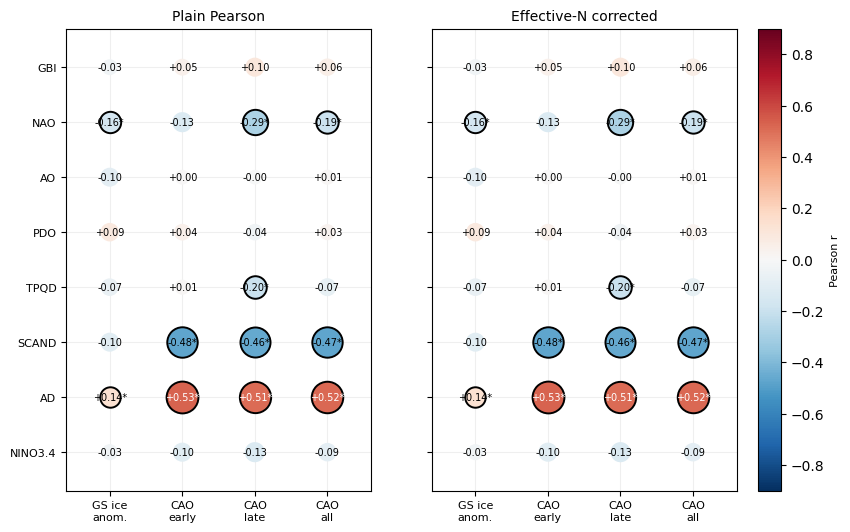

In [11]:
log_processing_step(logger, 'Creating comparison figure')

targets_order = list(TARGETS_MONTHLY.keys())
# Derived from targets_order itself, not hand-counted, so this can't
# silently fall out of sync with TARGETS_MONTHLY again (this is exactly
# what broke when CAO_all was added as a fourth target but this label
# list stayed hardcoded at 3 entries).
TARGET_LABEL_MAP = {'GS_ice_anom': 'GS ice\nanom.', 'CAO_early': 'CAO\nearly',
                    'CAO_late': 'CAO\nlate', 'CAO_all': 'CAO\nall'}
target_labels = [TARGET_LABEL_MAP.get(t, t) for t in targets_order]

fig, axes = plt.subplots(1, 2, figsize=(1.7 * len(targets_order) + 2.5,
                                        0.5 * len(INDEX_LABELS) + 2), sharey=True)
norm = TwoSlopeNorm(vmin=-VLIM, vcenter=0, vmax=VLIM)
cmap = plt.get_cmap(CMAP)

for ax, p_col, title in zip(axes, ['p_plain', 'p_effn'],
                            ['Plain Pearson', 'Effective-N corrected']):
    for j, tgt in enumerate(targets_order):
        for i, lab in enumerate(INDEX_LABELS):
            row = results[(results['index'] == lab) & (results['target'] == tgt)]
            if row.empty or not np.isfinite(row['r'].values[0]):
                continue
            rv = row['r'].values[0]
            pv = row[p_col].values[0]
            y = len(INDEX_LABELS) - 1 - i
            sig = np.isfinite(pv) and pv < P_THRESHOLD
            ax.scatter(j, y, s=110 + 780 * abs(rv), c=[cmap(norm(rv))],
                      edgecolors='k' if sig else 'none', linewidths=1.4, zorder=3)
            star = '*' if sig else ''
            ax.text(j, y, f'{rv:+.2f}{star}', ha='center', va='center',
                   fontsize=7, zorder=4, color='w' if abs(rv) > 0.5 else 'k')
    ax.set_xticks(range(len(targets_order)))
    ax.set_xticklabels(target_labels, fontsize=8)
    ax.set_xlim(-0.6, len(targets_order) - 0.4)
    ax.set_ylim(-0.7, len(INDEX_LABELS) - 0.3)
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_yticks(range(len(INDEX_LABELS)))
axes[0].set_yticklabels(INDEX_LABELS[::-1], fontsize=8)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=axes, fraction=0.04, pad=0.03)
cb.set_label('Pearson r', fontsize=8)

fname = 'monthly_ondjfma_correlations.png'
fig.savefig(OUTPUT_DIR / fname, dpi=DPI, bbox_inches='tight')
log_output_file(logger, 'figure', OUTPUT_DIR / fname)
plt.show()


In [12]:
results.to_csv(PROCESSED_DIR / 'monthly_ondjfma_correlations.csv', index=False)
log_output_file(logger, 'processed_data', PROCESSED_DIR)
log_completion(logger, start_time)


INFO     | Created processed_data: monthly_ondjfma_correlations
INFO     | ======================================================================
INFO     | Analysis completed successfully
INFO     | Total elapsed time: 0:00:39
INFO     | ======================================================================


In [13]:
methods = f"""# Monthly ONDJFMA correlations: Methodology

## Question
Does an index's monthly anomaly track the ice/CAO state in the same
month, with no lag -- as opposed to the trimmed matrix's DJFM winter-mean
correlations, which ask whether whole winters with a stronger index tend
to have more/less ice overall.

## Targets
- GS ice: monthly extent (NOT the winter-maximum metric used elsewhere),
  anomaly relative to a per-calendar-month climatology over
  {ANALYSIS_START}-{ANALYSIS_END}.
- CAO_early / CAO_late: monthly CAO index recomputed from ERA5 using
  figure_06's exact method (Greenland Sea polygon mask, land mask, 15%
  SIC threshold, {PRESSURE_LEVEL} hPa potential temperature), split by
  month into Oct-Jan / Feb-Apr subsets. NOT anomalised by default (see
  builder script comment for the flag to enable this).
- CAO_all: the same monthly CAO series, all ONDJFMA months together, no
  early/late split -- used by the combined figure's unfiltered triplet.

## Predictors
Climate indices, monthly, restricted to ONDJFMA, not further anomalised
(already standardised departures from their source agencies).

## Significance
Two methods reported side by side:
- Plain Pearson: standard scipy test, treats all ONDJFMA months as
  independent. Overstates significance.
- Effective-N (Bretherton et al. 1999): lag-1 autocorrelation estimated
  from genuine within-winter consecutive-month pairs only (Oct-Nov
  through Mar-Apr); the Apr-to-next-October gap is explicitly excluded
  from this estimate rather than treated as an ordinary 1-month lag.
  Neff = N*(1-r1x*r1y)/(1+r1x*r1y); p from a t-test on Neff-2 dof.

## Caveat
This notebook could not be run against real ERA5/OSISAF data in the
environment that built it. The effective-N and gap-aware lag-1 logic is
validated against synthetic data (SELFTEST cell); the real-data loading
and CAO recomputation are syntax-checked only, not run end-to-end.
"""
with open(OUTPUT_METHODS_DIR / 'monthly_ondjfma_correlations_methods.md', 'w') as f:
    f.write(methods)
print(methods)


# Monthly ONDJFMA correlations: Methodology

## Question
Does an index's monthly anomaly track the ice/CAO state in the same
month, with no lag -- as opposed to the trimmed matrix's DJFM winter-mean
correlations, which ask whether whole winters with a stronger index tend
to have more/less ice overall.

## Targets
- GS ice: monthly extent (NOT the winter-maximum metric used elsewhere),
  anomaly relative to a per-calendar-month climatology over
  1979-2025.
- CAO_early / CAO_late: monthly CAO index recomputed from ERA5 using
  figure_06's exact method (Greenland Sea polygon mask, land mask, 15%
  SIC threshold, 850 hPa potential temperature), split by
  month into Oct-Jan / Feb-Apr subsets. NOT anomalised by default (see
  builder script comment for the flag to enable this).
- CAO_all: the same monthly CAO series, all ONDJFMA months together, no
  early/late split -- used by the combined figure's unfiltered triplet.

## Predictors
Climate indices, monthly, restricted to ONDJFMA, not fur